# GitSkills — data analysis

Uses the CSV files built by `data_cleaning.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

skills = pd.read_csv(DATA_DIR / "skills_copied.csv")
repos = pd.read_csv(DATA_DIR / "repos_clean.csv")
adoptions = pd.read_csv(DATA_DIR / "adoptions.csv")

## RQ1 — Do copied skills cross language boundaries?

We keep skills copied by at least 2 eligible owners, with one row per skill and owner. If an
owner has the skill in several repositories, we keep their most frequent language.

A skill is `cross_language` if its owners use more than one primary language, `siloed` otherwise.

In [2]:
rq1_ids = skills.loc[skills["n_owners_eligible"] >= 2, "skill_id"]
eligible_repos = repos.loc[repos["eligible"] == 1, ["repo_id", "owner", "language"]]

owner_adoptions = (adoptions[adoptions["skill_id"].isin(rq1_ids)]
                   .merge(eligible_repos, on="repo_id")
                   .groupby(["skill_id", "owner", "language"]).size().rename("n")
                   .reset_index()
                   .sort_values("n", ascending=False, kind="stable")
                   .drop_duplicates(["skill_id", "owner"]))

rq1 = owner_adoptions.groupby("skill_id").agg(
    n_owners=("owner", "size"), n_languages=("language", "nunique"))
rq1["spread_class"] = "siloed"
rq1.loc[rq1["n_languages"] > 1, "spread_class"] = "cross_language"
rq1["adopters"] = pd.cut(rq1["n_owners"], [1, 2, 5, 20, np.inf], labels=["2", "3-5", "6-20", ">20"])

print(f"{len(rq1):,} skills")
pd.crosstab(rq1["adopters"], rq1["spread_class"], normalize="index", margins=True).round(3)

67,061 skills


spread_class,cross_language,siloed
adopters,,
2,0.410,0.590
3-5,0.646,0.354
6-20,0.840,0.160
>20,0.994,0.006
All,0.576,0.424


### Comparison with chance

Most owners use TypeScript or Python, so even two random owners often use different
languages. To know if the observed crossing rate is high or low, we compare it to
what we would see if language played no role: we shuffle the languages of the skill/owner
rows at random and recompute the rate, 1,000 times.

If the observed rate is below the expected one, skills tend to stay within their language.

In [3]:
N_PERMUTATIONS = 1000
rng = np.random.default_rng(42)

skill_codes, _ = pd.factorize(owner_adoptions["skill_id"])
language_codes, _ = pd.factorize(owner_adoptions["language"])
adopters = rq1["adopters"].reindex(owner_adoptions["skill_id"].unique()).to_numpy()


def crossing_rate(language):
    # Share of skills found in more than one language, per adopters group and overall
    crosses = pd.Series(language).groupby(skill_codes).nunique() > 1
    rates = crosses.groupby(adopters, observed=True).mean()
    rates["all"] = crosses.mean()
    return rates


observed = crossing_rate(language_codes)
expected = pd.concat([crossing_rate(rng.permutation(language_codes))
                      for _ in range(N_PERMUTATIONS)], axis=1)

results = pd.DataFrame({
    "observed": observed,
    "expected": expected.mean(axis=1),
    "p_value": ((expected.T <= observed).sum() + 1) / (N_PERMUTATIONS + 1),
}).round(3).rename_axis("adopters").reset_index()
results

,adopters,observed,expected,p_value
0,2,0.410,0.762,0.001
1,3-5,0.646,0.953,0.001
2,6-20,0.840,0.999,0.001
3,>20,0.994,1.000,0.001
4,all,0.576,0.870,0.001


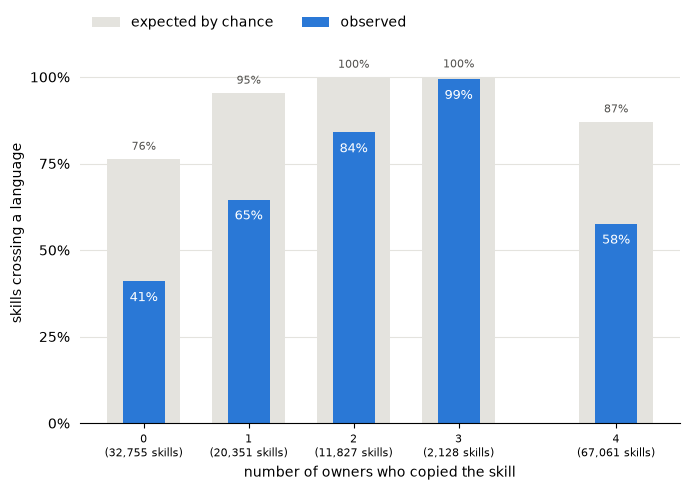

In [4]:
n_skills = list(rq1["adopters"].value_counts().sort_index()) + [len(rq1)]
labels = [f"{group}\n({n:,} skills)" for group, n in zip(results.index, n_skills)]
x = np.array([0, 1, 2, 3, 4.5])  # small gap before "all"

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(x, results["expected"], width=0.7, color="#e4e3de", label="expected by chance")
ax.bar(x, results["observed"], width=0.4, color="#2a78d6", label="observed")
for xi, obs, exp in zip(x, results["observed"], results["expected"]):
    ax.text(xi, obs - 0.03, f"{obs:.0%}", ha="center", va="top", fontsize=9, color="white")
    ax.text(xi, exp + 0.02, f"{exp:.0%}", ha="center", va="bottom", fontsize=8, color="#52514e")

ax.set_xticks(x, labels, fontsize=8)
ax.set_xlabel("number of owners who copied the skill")
ax.set_ylabel("skills crossing a language")
ax.set_ylim(0, 1.1)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.grid(True, color="#e4e3de", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(left=False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "rq1_language_crossing.pdf")
plt.show()

### Which languages share skills?

For each skill, every pair of its owners gives a pair of languages. We count these pairs
(weighted by 1 / (number of owners − 1) so that very popular skills do not dominate) and
divide by the count expected if owners were paired at random. Above 1 means the two languages
share more skills than chance. On the other side, below 1 mean less. Only the 12 largest languages are shown.

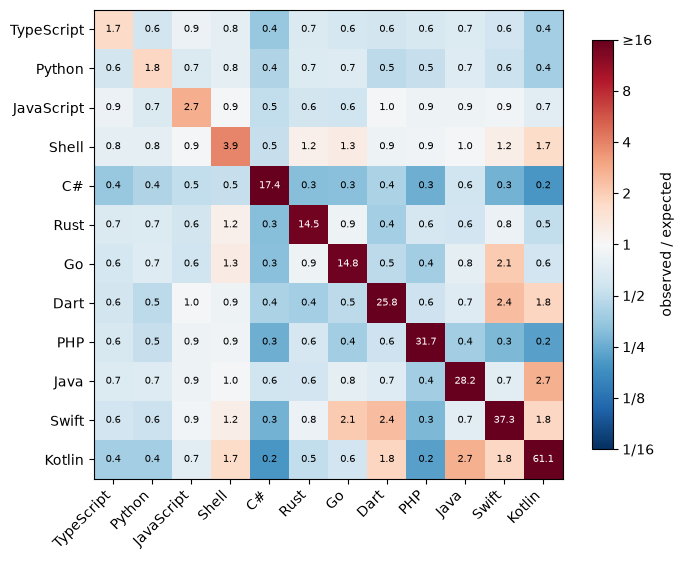

In [5]:
counts = pd.crosstab(owner_adoptions["skill_id"], owner_adoptions["language"])
C = counts.to_numpy()
weighted = C / (C.sum(axis=1, keepdims=True) - 1)

pairs = weighted.T @ C - np.diag(weighted.sum(axis=0))
totals = C.sum(axis=0)
ratio = pd.DataFrame(pairs / np.outer(totals, totals) * totals.sum(),
                     index=counts.columns, columns=counts.columns)

top = owner_adoptions["language"].value_counts().index[:12]
ratio = ratio.loc[top, top]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(np.log2(ratio), cmap="RdBu_r", vmin=-4, vmax=4)
for i in range(len(top)):
    for j in range(len(top)):
        color = "white" if ratio.iat[i, j] > 6 else "black"
        ax.text(j, i, f"{ratio.iat[i, j]:.1f}", ha="center", va="center", fontsize=7, color=color)
ax.set_xticks(range(len(top)), top, rotation=45, ha="right")
ax.set_yticks(range(len(top)), top)
bar = fig.colorbar(im, ax=ax, shrink=0.8, ticks=range(-4, 5))
bar.ax.set_yticklabels(["1/16", "1/8", "1/4", "1/2", "1", "2", "4", "8", "≥16"])
bar.set_label("observed / expected")
fig.tight_layout()
fig.savefig(FIG_DIR / "rq1_language_heatmap.pdf")
plt.show()

Small languages get large ratios easily, so we also look at the plain share of a
language's co-adopters that use the same language, compared to its share of all adoptions.

In [6]:
pd.DataFrame({
    "share_of_adoptions": totals / totals.sum(),
    "same_language_share": np.diag(pairs) / totals,
}, index=counts.columns).loc[top].round(3)

,share_of_adoptions,same_language_share
language,,
TypeScript,0.336,0.570
Python,0.324,0.578
JavaScript,0.120,0.328
Shell,0.051,0.196
C#,0.032,0.554
Rust,0.023,0.329
Go,0.022,0.326
Dart,0.014,0.357
PHP,0.013,0.397
